# Income Pipeline, Part 4: Merge in SQLite and Visualize

**Goal:** combine the three cleaned sources (IRS flat file, Wikipedia web table, census API data) in a SQLite database and look at what they show about the highest-income ZIP codes.

**Steps:** confirm each source has exactly one row per ZIP code, load all three into an in-memory SQLite database, LEFT JOIN them on ZIP code starting from the 100 highest-income ZIP codes, and chart the results.

**Key results:**
- 95 of the 100 top-income ZIP codes match a census record and 81 match IRS data.
- The highest per capita income is in Montchanin, Delaware ($654,485), a ZIP code with 68 residents.
- New York and California each have 18 of the top 100 ZIP codes.
- 28 of the 100 have fewer than 1,000 people, and the two income measures barely agree (correlation 0.05), so per capita income for tiny ZIP codes should be read with caution.

**Tools:** Python (pandas, sqlite3, matplotlib)

**Context:** master's coursework (DSC540 term project), cleaned up and corrected for this portfolio. This is part of a four-notebook pipeline: 1 flat file, 2 web scraping, 3 API, 4 merge and visualize.

## 1. Load the three cleaned sources into SQLite

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

income = pd.read_csv('Data/Income_flat.csv', dtype={'ZipCode': str})              # flat file (IRS)
top_income = pd.read_csv('Data/TopIncome_wiki.csv', dtype={'ZipCode': str})       # web (Wikipedia, July 2024)
census = pd.read_csv('Data/Census_API.csv', dtype={'ZipCode': str})              # API (Census via Kaggle)
top_income['ZipCode'] = top_income['ZipCode'].str.zfill(5)
for name, d in [('IRS income', income), ('Top income ZIPs', top_income), ('Census population', census)]:
    print(f"{name:18s} {len(d):>6,} rows   one row per ZIP code: {not d['ZipCode'].duplicated().any()}")

conn = sqlite3.connect(':memory:')
_ = income.to_sql('irs_income', conn, index=False)
_ = top_income.to_sql('top_income', conn, index=False)
_ = census.to_sql('census_population', conn, index=False)

IRS income         27,786 rows   one row per ZIP code: True
Top income ZIPs       100 rows   one row per ZIP code: True
Census population  33,119 rows   one row per ZIP code: True


## 2. Merge with SQL
Each source has exactly one row per ZIP code, so a LEFT JOIN from the 100 top-income ZIP codes adds the IRS and census figures without duplicating rows.

In [2]:
merge_query = '''
SELECT
    t.Rank,
    t.ZipCode,
    t.City,
    t.State,
    t."Per CapitaIncome"                AS PerCapitaIncome,
    t.Population                        AS PopulationWiki,
    c.PopulationCensus,
    i.Num_Returns,
    i.Salaries_Wages_Thousands,
    i.Avg_Wages_Per_Return
FROM top_income AS t
LEFT JOIN irs_income        AS i ON t.ZipCode = i.ZipCode
LEFT JOIN census_population AS c ON t.ZipCode = c.ZipCode
ORDER BY t.Rank
'''
merged = pd.read_sql_query(merge_query, conn)
merged.to_csv('Data/merged_file.csv', index=False)
print(f'Merged rows: {len(merged)}   with IRS data: {merged["Num_Returns"].notna().sum()}   with census data: {merged["PopulationCensus"].notna().sum()}')
merged.head(10)

Merged rows: 100   with IRS data: 81   with census data: 95


,Rank,ZipCode,City,State,PerCapitaIncome,PopulationWiki,PopulationCensus,Num_Returns,Salaries_Wages_Thousands,Avg_Wages_Per_Return
0,1,19710,Montchanin,DE,654485,68,41.0,NaN,NaN,NaN
1,2,77010,Houston,TX,283189,76,366.0,422.0000,6.209900e+04,147154.0
2,3,19732,Rockland,DE,279424,77,25.0,NaN,NaN,NaN
3,4,33109,Miami Beach,FL,236238,467,594.0,305.0001,6.187900e+04,202882.0
4,5,33945,Pineland,FL,162075,79,57.0,NaN,NaN,NaN
5,6,12429,Esopus,NY,155540,51,281.0,NaN,NaN,NaN
6,7,89012,Henderson,NV,148899,175,29085.0,13656.0000,6.586820e+05,48234.0
7,8,94027,Atherton,CA,114359,6857,7089.0,3169.0000,1.112754e+06,351137.0
8,9,33921,Boca Grande,FL,107297,1500,1720.0,NaN,NaN,NaN
9,10,98243,Deer Harbor,WA,107173,141,507.0,NaN,NaN,NaN


In [3]:
# how many of the top-income ZIP codes are in each state
state_counts = pd.read_sql_query('SELECT State, COUNT(*) AS ZipCodes FROM top_income GROUP BY State ORDER BY ZipCodes DESC', conn)
print(state_counts.head(6).to_string(index=False))
conn.close()

State  ZipCodes
   NY        18
   CA        18
   NJ         7
   IL         7
   FL         7
   CT         7


## 3. Visualize

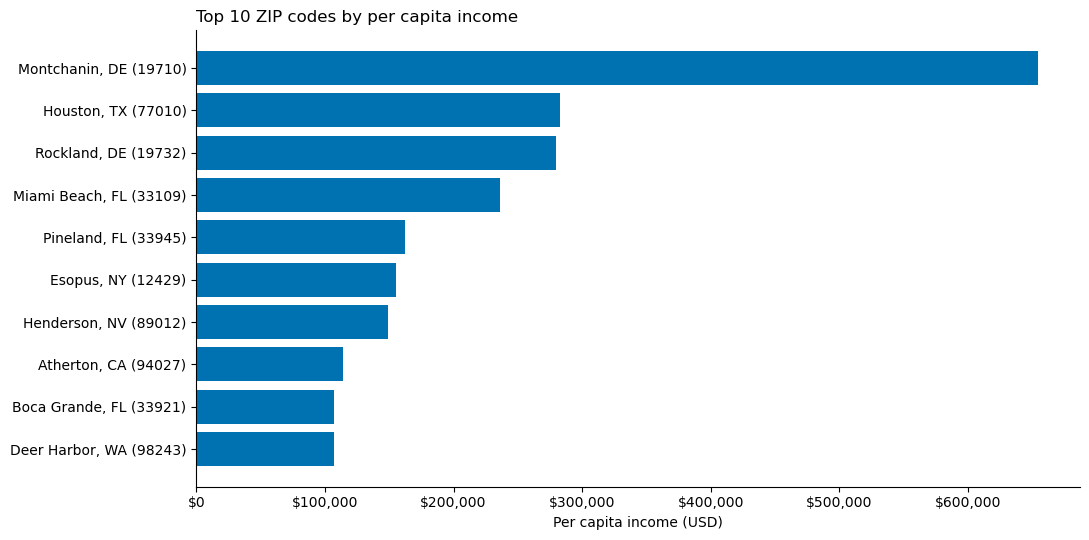

In [4]:
# Chart 1: the 10 ZIP codes with the highest per capita income
top10 = merged.head(10).copy()
top10['Label'] = top10['City'] + ', ' + top10['State'] + ' (' + top10['ZipCode'] + ')'
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(top10['Label'][::-1], top10['PerCapitaIncome'][::-1], color='#0072B2')
ax.set_title('Top 10 ZIP codes by per capita income', loc='left')
ax.set_xlabel('Per capita income (USD)'); ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

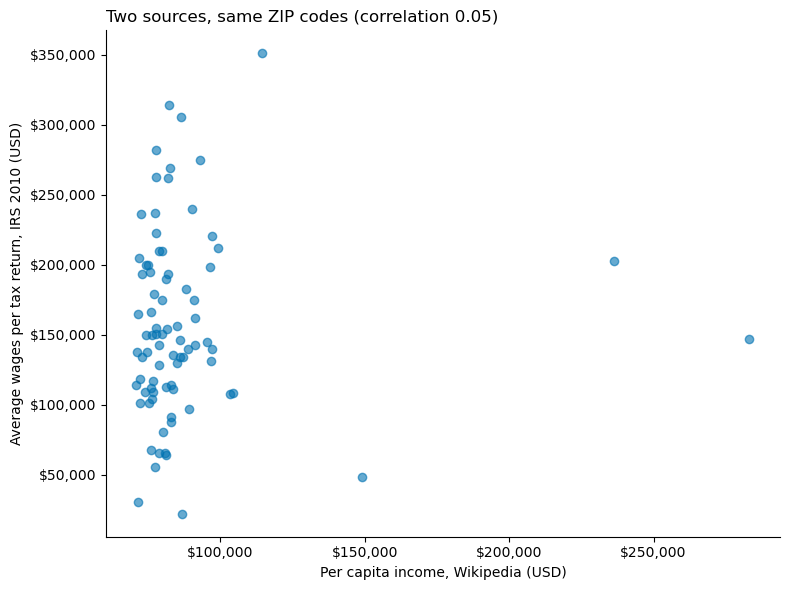

ZIP codes with both figures: 81   correlation: 0.05


In [5]:
# Chart 2: do the two income sources agree? Wikipedia per capita income vs. IRS average wages per return
both = merged.dropna(subset=['Avg_Wages_Per_Return'])
corr = both['PerCapitaIncome'].corr(both['Avg_Wages_Per_Return'])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(both['PerCapitaIncome'], both['Avg_Wages_Per_Return'], color='#0072B2', alpha=0.6)
ax.set_xlabel('Per capita income, Wikipedia (USD)'); ax.set_ylabel('Average wages per tax return, IRS 2010 (USD)')
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}')); ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))
ax.set_title(f'Two sources, same ZIP codes (correlation {corr:.2f})', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
print(f'ZIP codes with both figures: {len(both)}   correlation: {corr:.2f}')

count       100.0
mean      10247.0
std       15791.0
min           2.0
25%         647.0
50%        4021.0
75%       13574.0
max      102078.0
ZIP codes with fewer than 1,000 people: 28 of 100


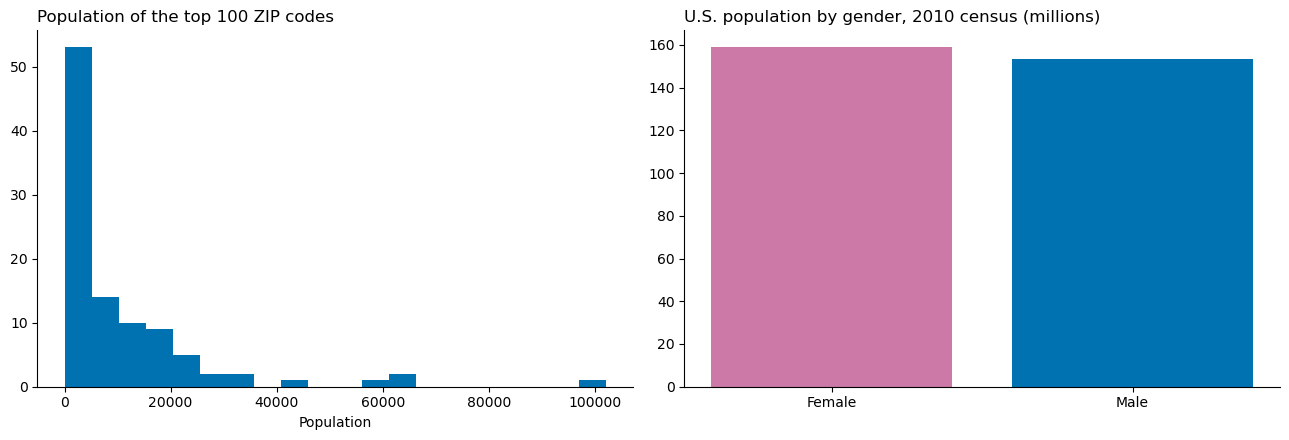

In [6]:
# Chart 3: population of the top-income ZIP codes (most are small)
print(merged['PopulationWiki'].describe().round(0).to_string())
print(f"ZIP codes with fewer than 1,000 people: {(merged['PopulationWiki'] < 1000).sum()} of {len(merged)}")
gender = pd.read_csv('Data/Census_gender_totals.csv', index_col=0)['PopulationCensus']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(merged['PopulationWiki'], bins=20, color='#0072B2')
axes[0].set_title('Population of the top 100 ZIP codes', loc='left'); axes[0].set_xlabel('Population')
axes[1].bar(gender.index.str.capitalize(), gender.values / 1e6, color=['#CC79A7', '#0072B2'])
axes[1].set_title('U.S. population by gender, 2010 census (millions)', loc='left')
for a in axes: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Findings
- **The merge works cleanly once each source has one row per ZIP code.** All 100 top-income ZIP codes are kept; 95 have a census population and 81 have IRS data (the IRS does not publish very small ZIP codes separately).
- **The top of the list is dominated by tiny places.** Montchanin, Delaware ($654,485 per capita) has 68 residents, Houston's 77010 has 76 and Rockland, Delaware has 77. The median population of the top 100 is 4,021, and 28 have fewer than 1,000 people, where a single very high earner can make per capita income look extreme.
- **The two income measures barely agree.** Wikipedia's per capita income and the IRS's 2010 average wages per return have a correlation of only 0.05 across the 81 ZIP codes that have both. They measure different things (all income per resident vs. wages per tax return) in different years, and wealth in these areas often comes from investments rather than wages. Atherton, California is the clearest case where both are high ($114,359 per capita; $351,137 average wages per return, the highest of any ZIP code in the IRS data).
- **Population sources do not always match.** Henderson, Nevada (89012) is listed with 175 residents on Wikipedia but 29,085 in the 2010 census, a sign that the web table's ZIP code area or figures should be checked.
- **Geography:** New York and California each hold 18 of the top 100 ZIP codes, followed by New Jersey, Illinois, Florida and Connecticut with 7 each.

**Correction note:** the original merge loaded the raw IRS and census tables (six income-bracket rows per ZIP code and many age and gender rows per ZIP code) and used GROUP BY without totals, so each ZIP code picked up one arbitrary row's wages and population rather than its total. Its census file also kept every row, so population by gender added up to 625 million, about twice the real figure. The original top-10 chart added per capita incomes together across ZIP codes in the same city. This version gives each source one row per ZIP code before merging, uses the census total rows, and charts ZIP codes individually. The original notebooks and outputs are in `earlier_versions/`.